In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Project paths
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

print("Project directory:", PROJECT_DIR)
print("Raw data folder exists:", RAW_DIR.exists())
print("Processed data folder exists:", PROCESSED_DIR.exists())

Project directory: c:\Users\ishar\OneDrive\Documents\MF-Analytics-Platform
Raw data folder exists: True
Processed data folder exists: True


In [2]:
# Load the main project datasets

fund_master = pd.read_csv(PROCESSED_DIR / "01_fund_master.csv")
nav_history = pd.read_csv(PROCESSED_DIR / "02_nav_history.csv")
aum_data = pd.read_csv(PROCESSED_DIR / "03_aum_by_fund_house.csv")
sip_data = pd.read_csv(PROCESSED_DIR / "04_monthly_sip_inflows.csv")
category_inflows = pd.read_csv(PROCESSED_DIR / "05_category_inflows.csv")
folio_data = pd.read_csv(PROCESSED_DIR / "06_industry_folio_count.csv")
performance = pd.read_csv(PROCESSED_DIR / "07_scheme_performance.csv")
transactions = pd.read_csv(PROCESSED_DIR / "08_investor_transactions.csv")
holdings = pd.read_csv(PROCESSED_DIR / "09_portfolio_holdings.csv")
benchmark_indices = pd.read_csv(PROCESSED_DIR / "10_benchmark_indices.csv")

print("All 10 main datasets loaded successfully!")

All 10 main datasets loaded successfully!


In [3]:
datasets = {
    "Fund Master": fund_master,
    "NAV History": nav_history,
    "AUM": aum_data,
    "SIP Inflows": sip_data,
    "Category Inflows": category_inflows,
    "Folio Count": folio_data,
    "Performance": performance,
    "Transactions": transactions,
    "Portfolio Holdings": holdings,
    "Benchmark Indices": benchmark_indices,
}

summary = pd.DataFrame([
    {
        "Dataset": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Missing Cells": int(df.isna().sum().sum()),
        "Duplicate Rows": int(df.duplicated().sum()),
    }
    for name, df in datasets.items()
])

summary

,Dataset,Rows,Columns,Missing Cells,Duplicate Rows
0,Fund Master,40,15,0,0
1,NAV History,46000,3,0,0
2,AUM,90,5,0,0
3,SIP Inflows,48,6,12,0
4,Category Inflows,144,3,0,0
5,Folio Count,21,6,0,0
6,Performance,40,19,0,0
7,Transactions,32778,13,0,0
8,Portfolio Holdings,322,8,0,0
9,Benchmark Indices,8050,3,0,0


In [4]:
# Fund Master Analysis

print("Total schemes:", len(fund_master))
print("Unique fund houses:", fund_master["fund_house"].nunique())

print("\nSchemes by category:")
display(
    fund_master["category"]
    .value_counts()
    .rename_axis("Category")
    .reset_index(name="Number of Schemes")
)

print("\nTop fund houses by number of schemes:")
display(
    fund_master["fund_house"]
    .value_counts()
    .head(10)
    .rename_axis("Fund House")
    .reset_index(name="Number of Schemes")
)

Total schemes: 40
Unique fund houses: 10

Schemes by category:


,Category,Number of Schemes
0,Equity,34
1,Debt,6



Top fund houses by number of schemes:


,Fund House,Number of Schemes
0,SBI Mutual Fund,5
1,HDFC Mutual Fund,5
2,ICICI Prudential MF,5
3,Nippon India MF,5
4,Kotak Mahindra MF,4
5,Axis Mutual Fund,4
6,Aditya Birla Sun Life MF,3
7,UTI Mutual Fund,3
8,Mirae Asset MF,3
9,DSP Mutual Fund,3


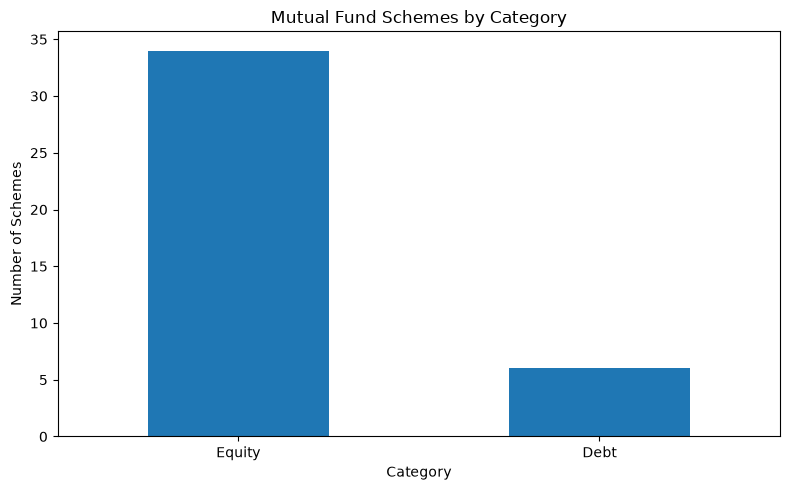

In [5]:
# Visualize scheme distribution by category

category_counts = fund_master["category"].value_counts()

plt.figure(figsize=(8, 5))
category_counts.plot(kind="bar")

plt.title("Mutual Fund Schemes by Category")
plt.xlabel("Category")
plt.ylabel("Number of Schemes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

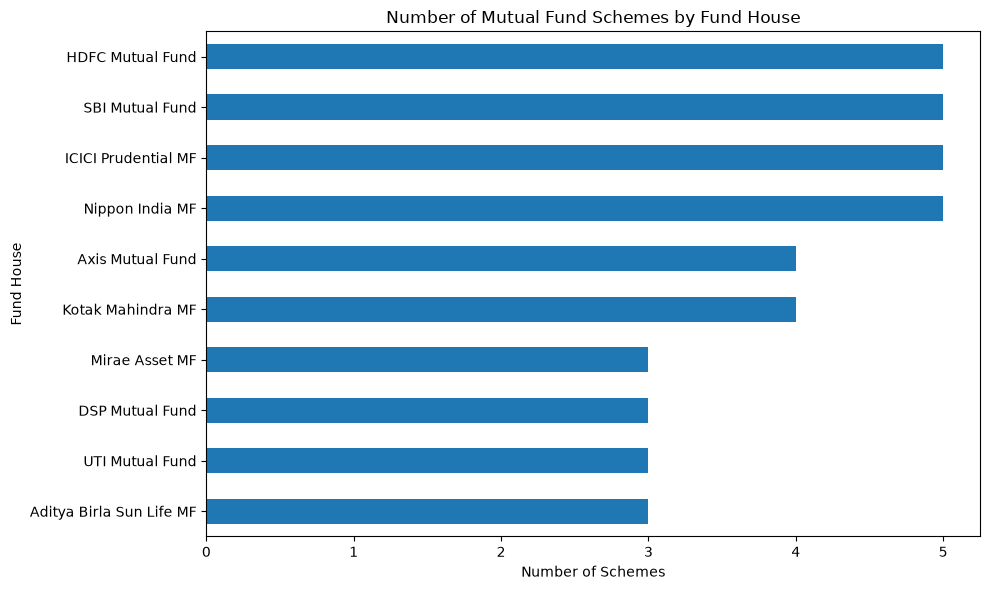

In [6]:
# Compare fund houses by number of schemes

fund_house_counts = (
    fund_master["fund_house"]
    .value_counts()
    .sort_values()
)

plt.figure(figsize=(10, 6))
fund_house_counts.plot(kind="barh")

plt.title("Number of Mutual Fund Schemes by Fund House")
plt.xlabel("Number of Schemes")
plt.ylabel("Fund House")
plt.tight_layout()
plt.show()

In [7]:
# Prepare NAV history for time-series analysis

nav_history["date"] = pd.to_datetime(nav_history["date"])

print("Total NAV records:", len(nav_history))
print("Unique funds:", nav_history["amfi_code"].nunique())
print("Start date:", nav_history["date"].min().date())
print("End date:", nav_history["date"].max().date())

display(nav_history.head())

Total NAV records: 46000
Unique funds: 40
Start date: 2022-01-03
End date: 2026-05-29


,amfi_code,date,nav
0,100016,2022-01-03,520.4608
1,100016,2022-01-04,515.0971
2,100016,2022-01-05,521.7239
3,100016,2022-01-06,515.7880
4,100016,2022-01-07,515.1639


In [8]:
# Display available fund schemes

display(
    fund_master[["amfi_code", "scheme_name", "fund_house", "category"]]
    .sort_values("scheme_name")
    .head(15)
)

,amfi_code,scheme_name,fund_house,category
28,101206,ABSL Frontline Equity Fund - Regular - Growth,Aditya Birla Sun Life MF,Equity
30,101208,ABSL Liquid Fund - Regular - Growth,Aditya Birla Sun Life MF,Debt
29,101207,ABSL Small Cap Fund - Regular - Growth,Aditya Birla Sun Life MF,Equity
25,119093,Axis Bluechip Fund - Direct - Growth,Axis Mutual Fund,Equity
24,119092,Axis Bluechip Fund - Regular - Growth,Axis Mutual Fund,Equity
26,119094,Axis Midcap Fund - Regular - Growth,Axis Mutual Fund,Equity
27,119095,Axis Small Cap Fund - Regular - Growth,Axis Mutual Fund,Equity
38,149323,DSP Midcap Fund - Regular - Growth,DSP Mutual Fund,Equity
39,149324,DSP Small Cap Fund - Regular - Growth,DSP Mutual Fund,Equity
37,149322,DSP Top 100 Equity Fund - Regular - Growth,DSP Mutual Fund,Equity


Fund: HDFC Top 100 Fund - Regular Plan - Growth
NAV records: 1150
Starting NAV: 520.46
Latest NAV: 583.61


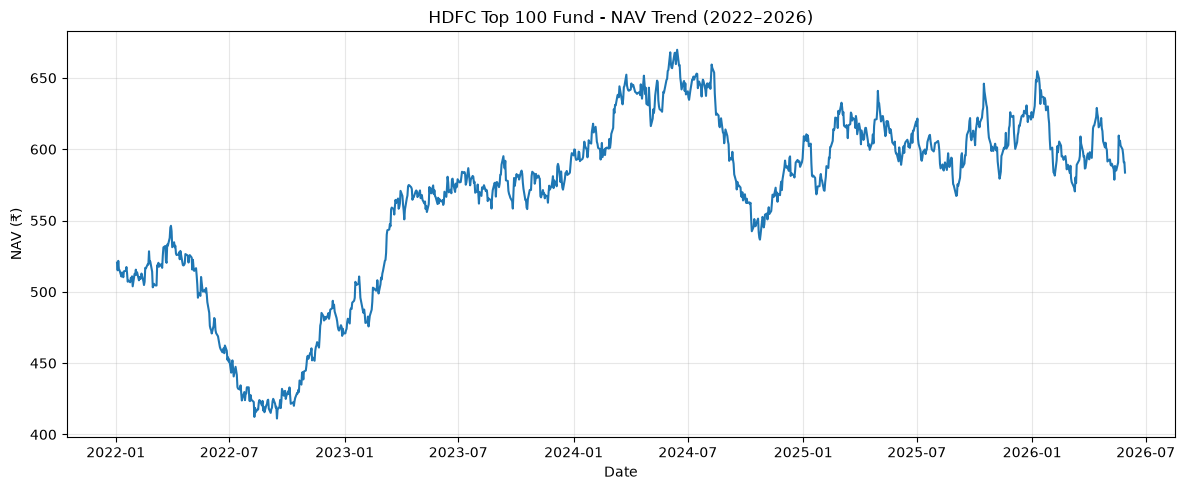

In [9]:
# Select HDFC Top 100 Fund - Regular Plan - Growth

selected_code = 100016

hdfc_nav = nav_history[
    nav_history["amfi_code"] == selected_code
].copy()

hdfc_nav = hdfc_nav.sort_values("date")

print("Fund:", fund_master.loc[
    fund_master["amfi_code"].astype(str) == str(selected_code),
    "scheme_name"
].iloc[0])

print("NAV records:", len(hdfc_nav))
print("Starting NAV:", round(hdfc_nav.iloc[0]["nav"], 2))
print("Latest NAV:", round(hdfc_nav.iloc[-1]["nav"], 2))

# Plot NAV trend
plt.figure(figsize=(12, 5))
plt.plot(hdfc_nav["date"], hdfc_nav["nav"])

plt.title("HDFC Top 100 Fund - NAV Trend (2022–2026)")
plt.xlabel("Date")
plt.ylabel("NAV (₹)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
# Calculate overall NAV change

starting_nav = hdfc_nav.iloc[0]["nav"]
latest_nav = hdfc_nav.iloc[-1]["nav"]

nav_change = latest_nav - starting_nav
nav_change_pct = ((latest_nav - starting_nav) / starting_nav) * 100

print(f"Starting NAV: ₹{starting_nav:.2f}")
print(f"Latest NAV: ₹{latest_nav:.2f}")
print(f"NAV change: ₹{nav_change:.2f}")
print(f"Overall NAV change: {nav_change_pct:.2f}%")

Starting NAV: ₹520.46
Latest NAV: ₹583.61
NAV change: ₹63.15
Overall NAV change: 12.13%


In [11]:
# Find maximum and minimum NAV

max_nav_row = hdfc_nav.loc[hdfc_nav["nav"].idxmax()]
min_nav_row = hdfc_nav.loc[hdfc_nav["nav"].idxmin()]

print("Maximum NAV:", round(max_nav_row["nav"], 2))
print("Maximum NAV date:", max_nav_row["date"].date())

print("\nMinimum NAV:", round(min_nav_row["nav"], 2))
print("Minimum NAV date:", min_nav_row["date"].date())

Maximum NAV: 669.72
Maximum NAV date: 2024-06-14

Minimum NAV: 411.18
Minimum NAV date: 2022-09-15


In [12]:
# Calculate running peak and drawdown

hdfc_nav["running_peak"] = hdfc_nav["nav"].cummax()

hdfc_nav["drawdown_pct"] = (
    (hdfc_nav["nav"] - hdfc_nav["running_peak"])
    / hdfc_nav["running_peak"]
) * 100

max_drawdown_row = hdfc_nav.loc[hdfc_nav["drawdown_pct"].idxmin()]

print(f"Maximum Drawdown: {max_drawdown_row['drawdown_pct']:.2f}%")
print("Date of Maximum Drawdown:", max_drawdown_row["date"].date())
print(f"NAV at that point: ₹{max_drawdown_row['nav']:.2f}")
print(f"Previous Running Peak: ₹{max_drawdown_row['running_peak']:.2f}")

Maximum Drawdown: -24.73%
Date of Maximum Drawdown: 2022-09-15
NAV at that point: ₹411.18
Previous Running Peak: ₹546.30


In [1]:
# Visualize HDFC Top 100 Fund drawdown

plt.figure(figsize=(12, 5))

plt.plot(
    hdfc_nav["date"],
    hdfc_nav["drawdown_pct"]
)

plt.axhline(y=0, linestyle="--")

plt.title("HDFC Top 100 Fund - Historical Drawdown")
plt.xlabel("Date")
plt.ylabel("Drawdown (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined

In [2]:
import matplotlib.pyplot as plt

In [3]:
plt.figure(figsize=(12, 5))

plt.plot(hdfc_nav["date"], hdfc_nav["drawdown_pct"])
plt.axhline(y=0, linestyle="--")

plt.title("HDFC Top 100 Fund - Historical Drawdown")
plt.xlabel("Date")
plt.ylabel("Drawdown (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

NameError: name 'hdfc_nav' is not defined

<Figure size 1200x500 with 0 Axes>

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

# Load and prepare NAV data
nav_history = pd.read_csv(PROCESSED_DIR / "02_nav_history.csv")
nav_history["date"] = pd.to_datetime(nav_history["date"])

hdfc_nav = nav_history[
    nav_history["amfi_code"].astype(str) == "100016"
].copy()

hdfc_nav = hdfc_nav.sort_values("date")

# Calculate running peak and drawdown
hdfc_nav["running_peak"] = hdfc_nav["nav"].cummax()

hdfc_nav["drawdown_pct"] = (
    (hdfc_nav["nav"] - hdfc_nav["running_peak"])
    / hdfc_nav["running_peak"]
) * 100

print("NAV records:", len(hdfc_nav))
print(f"Maximum drawdown: {hdfc_nav['drawdown_pct'].min():.2f}%")

NameError: name 'PROCESSED_DIR' is not defined

NAV records: 1150
Maximum drawdown: -24.73%


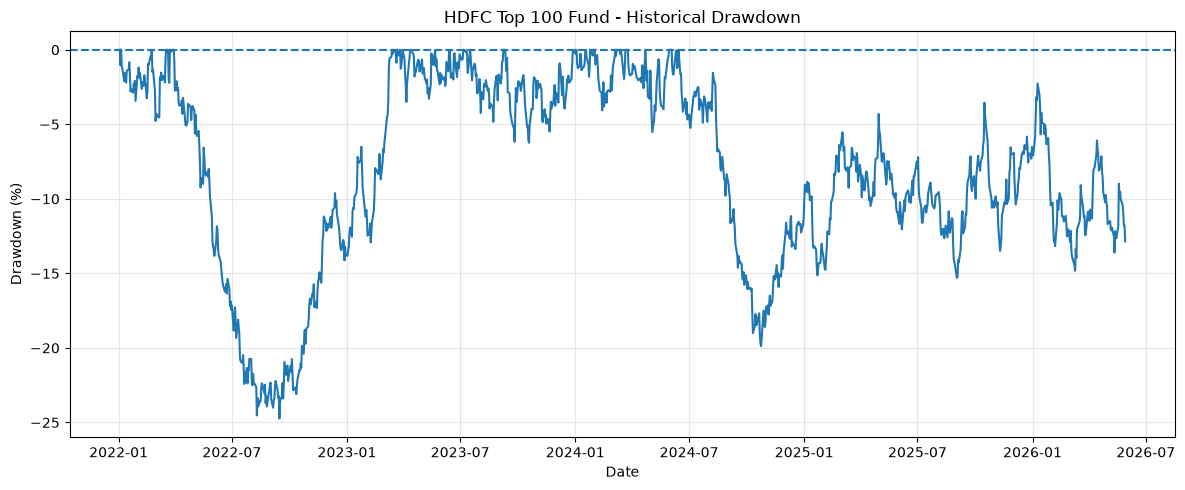

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Find project folder automatically
cwd = Path.cwd()

if cwd.name == "notebooks":
    project_dir = cwd.parent
else:
    project_dir = cwd

processed_dir = project_dir / "data" / "processed"

# Load HDFC NAV data
nav_history = pd.read_csv(processed_dir / "02_nav_history.csv")
nav_history["date"] = pd.to_datetime(nav_history["date"])

hdfc_nav = nav_history[
    nav_history["amfi_code"].astype(str) == "100016"
].copy()

hdfc_nav = hdfc_nav.sort_values("date")

# Calculate drawdown
hdfc_nav["running_peak"] = hdfc_nav["nav"].cummax()
hdfc_nav["drawdown_pct"] = (
    (hdfc_nav["nav"] - hdfc_nav["running_peak"])
    / hdfc_nav["running_peak"]
) * 100

print("NAV records:", len(hdfc_nav))
print(f"Maximum drawdown: {hdfc_nav['drawdown_pct'].min():.2f}%")

# Plot drawdown
plt.figure(figsize=(12, 5))
plt.plot(hdfc_nav["date"], hdfc_nav["drawdown_pct"])
plt.axhline(y=0, linestyle="--")
plt.title("HDFC Top 100 Fund - Historical Drawdown")
plt.xlabel("Date")
plt.ylabel("Drawdown (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
# Top 10 funds by 5-year return

top_10_funds = performance.sort_values(
    by="return_5yr_pct",
    ascending=False
).head(10)

display(
    top_10_funds[
        ["scheme_name", "fund_house", "category", "return_5yr_pct"]
    ]
)

NameError: name 'performance' is not defined

In [7]:
import pandas as pd
from pathlib import Path

# Locate the processed data folder
cwd = Path.cwd()
project_dir = cwd.parent if cwd.name == "notebooks" else cwd
processed_dir = project_dir / "data" / "processed"

# Load performance data
performance = pd.read_csv(
    processed_dir / "07_scheme_performance.csv"
)

# Select top 10 funds by 5-year return
top_10_funds = performance.sort_values(
    by="return_5yr_pct",
    ascending=False
).head(10)

display(
    top_10_funds[
        ["scheme_name", "fund_house", "category", "return_5yr_pct"]
    ].reset_index(drop=True)
)

,scheme_name,fund_house,category,return_5yr_pct
0,ABSL Small Cap Fund - Regular - Growth,Aditya Birla Sun Life MF,Small Cap,23.80
1,Axis Small Cap Fund - Regular - Growth,Axis Mutual Fund,Small Cap,22.62
2,Nippon India Small Cap Fund - Regular - Growth,Nippon India MF,Small Cap,21.88
3,SBI Small Cap Fund - Direct Plan - Growth,SBI Mutual Fund,Small Cap,21.82
4,SBI Small Cap Fund - Regular Plan - Growth,SBI Mutual Fund,Small Cap,20.67
5,DSP Small Cap Fund - Regular - Growth,DSP Mutual Fund,Small Cap,20.61
6,DSP Midcap Fund - Regular - Growth,DSP Mutual Fund,Mid Cap,19.00
7,Axis Midcap Fund - Regular - Growth,Axis Mutual Fund,Mid Cap,18.94
8,Kotak Emerging Equity Fund - Regular - Growth,Kotak Mahindra MF,Mid Cap,17.75
9,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,HDFC Mutual Fund,Mid Cap,17.69


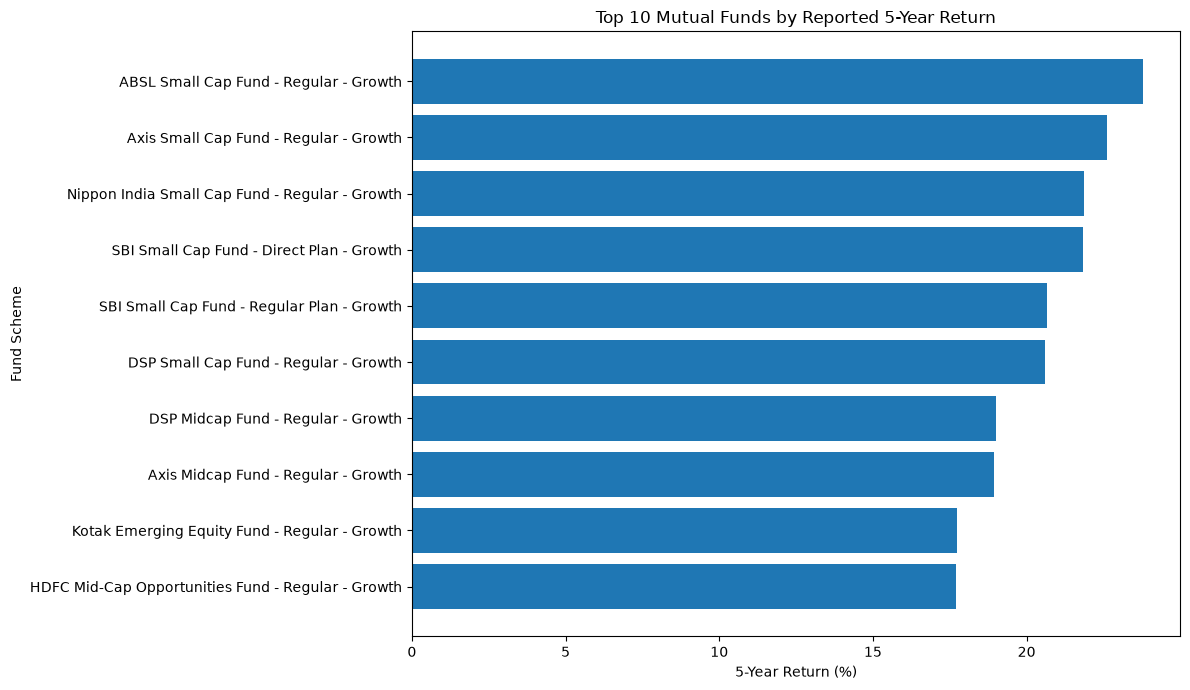

In [8]:
# Top 10 funds by 5-year return

chart_data = top_10_funds.sort_values("return_5yr_pct")

plt.figure(figsize=(12, 7))

plt.barh(
    chart_data["scheme_name"],
    chart_data["return_5yr_pct"]
)

plt.title("Top 10 Mutual Funds by Reported 5-Year Return")
plt.xlabel("5-Year Return (%)")
plt.ylabel("Fund Scheme")
plt.tight_layout()
plt.show()

In [10]:
import matplotlib.pyplot as plt

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Locate project folder
cwd = Path.cwd()
project_dir = cwd.parent if cwd.name == "notebooks" else cwd
processed_dir = project_dir / "data" / "processed"

# Load monthly SIP data
sip_data = pd.read_csv(
    processed_dir / "04_monthly_sip_inflows.csv"
)

sip_data["month"] = pd.to_datetime(sip_data["month"])

print("Total records:", len(sip_data))
print("First month:", sip_data["month"].min().strftime("%Y-%m"))
print("Last month:", sip_data["month"].max().strftime("%Y-%m"))

display(sip_data.head())

Total records: 48
First month: 2022-01
Last month: 2025-12


,month,sip_inflow_crore,active_sip_accounts_crore,new_sip_accounts_lakh,sip_aum_lakh_crore,yoy_growth_pct
0,2022-01-01,11517,4.91,9.10,4.80,NaN
1,2022-02-01,11438,4.93,8.20,4.85,NaN
2,2022-03-01,12328,5.09,10.50,5.01,NaN
3,2022-04-01,11863,5.48,9.52,5.12,NaN
4,2022-05-01,12286,5.55,8.10,5.15,NaN


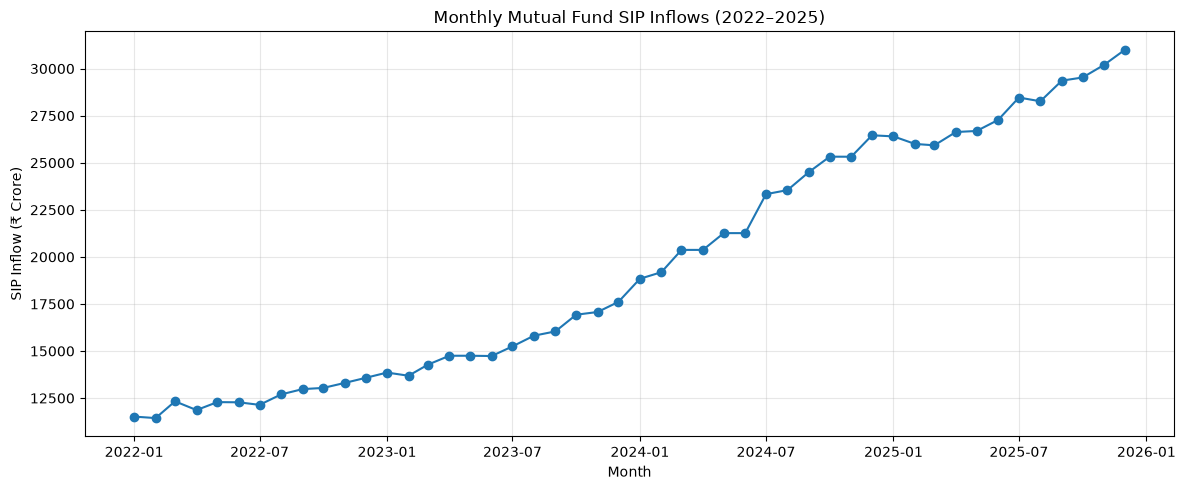

In [12]:
plt.figure(figsize=(12, 5))

plt.plot(
    sip_data["month"],
    sip_data["sip_inflow_crore"],
    marker="o"
)

plt.title("Monthly Mutual Fund SIP Inflows (2022–2025)")
plt.xlabel("Month")
plt.ylabel("SIP Inflow (₹ Crore)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
# Find highest and lowest SIP inflow months

highest_sip = sip_data.loc[
    sip_data["sip_inflow_crore"].idxmax()
]

lowest_sip = sip_data.loc[
    sip_data["sip_inflow_crore"].idxmin()
]

print(
    f"Highest SIP inflow: ₹{highest_sip['sip_inflow_crore']:,.0f} crore"
)
print(
    "Month:",
    highest_sip["month"].strftime("%B %Y")
)

print()

print(
    f"Lowest SIP inflow: ₹{lowest_sip['sip_inflow_crore']:,.0f} crore"
)
print(
    "Month:",
    lowest_sip["month"].strftime("%B %Y")
)

Highest SIP inflow: ₹31,002 crore
Month: December 2025

Lowest SIP inflow: ₹11,438 crore
Month: February 2022


### Monthly SIP Inflow Analysis

**Observation:** The monthly SIP inflow series shows an overall upward trend during the available analysis period.

**Business relevance:** Rising SIP inflows can indicate increasing contributions through systematic investment plans in the dataset. The trend alone does not establish the cause of the increase.

**Next analysis:** Identify the months with the highest and lowest inflows and compare annual averages to understand the trend more clearly.

,transaction_count,total_amount_inr
transaction_type,,
SIP,19716,217233491
Lumpsum,8095,2059821448
Redemption,4967,1244525491


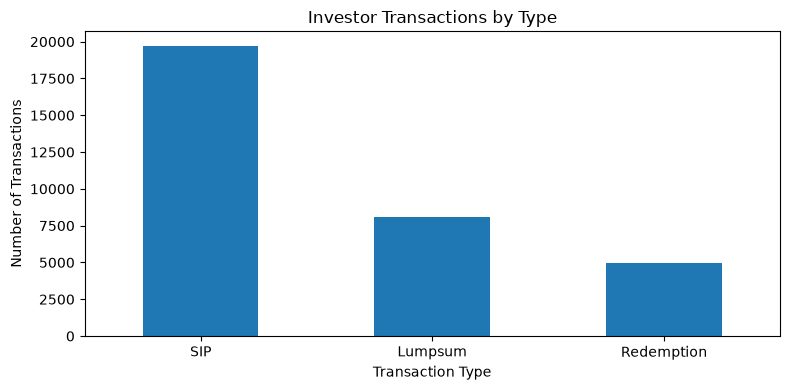

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

cwd = Path.cwd()
project_dir = cwd.parent if cwd.name == "notebooks" else cwd

transactions = pd.read_csv(
    project_dir / "data" / "processed" / "08_investor_transactions.csv"
)

summary = transactions.groupby("transaction_type").agg(
    transaction_count=("amount_inr", "count"),
    total_amount_inr=("amount_inr", "sum")
).sort_values("transaction_count", ascending=False)

display(summary)

summary["transaction_count"].plot(kind="bar", figsize=(8, 4))
plt.title("Investor Transactions by Type")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()